# Distilling a Neural Network into Soft Decision Tree

* Implementation based on [[Frosst & Hinton, 2017](http://arxiv.org/abs/1711.09784)]

## Imports

In [2]:
import numpy as np

import os
import tensorflow as tf

from models import ConvNet, SoftBinaryDecisionTree
# from models.unlearning import UnlearningSDT
from models.utils import brand_new_tfsession, draw_tree
from tensorflow.keras.callbacks import EarlyStopping, Callback

sess = brand_new_tfsession()

## Dataset

In [3]:
# load MNIST data
mnist = tf.keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# add channel dim
x_train, x_test = x_train[..., np.newaxis], x_test[..., np.newaxis]

# hold out last 10000 training samples for validation
x_valid, y_valid = x_train[-10000:], y_train[-10000:]
x_train, y_train = x_train[:-10000], y_train[:-10000]

print(x_train.shape, y_train.shape, x_valid.shape, y_valid.shape, x_test.shape, y_test.shape)

(50000, 28, 28, 1) (50000,) (10000, 28, 28, 1) (10000,) (10000, 28, 28, 1) (10000,)


In [4]:
# retrieve image and label shapes from training data
img_rows, img_cols, img_chans = x_train.shape[1:]
n_classes = np.unique(y_train).shape[0]

print(img_rows, img_cols, img_chans, n_classes)

28 28 1 10


In [5]:
# convert labels to 1-hot vectors
y_train = tf.keras.utils.to_categorical(y_train, n_classes)
y_valid = tf.keras.utils.to_categorical(y_valid, n_classes)
y_test = tf.keras.utils.to_categorical(y_test, n_classes)

print(y_train.shape, y_valid.shape, y_test.shape)

(50000, 10) (10000, 10) (10000, 10)


In [6]:
# normalize inputs and cast to float
x_train = (x_train / np.max(x_train)).astype(np.float32)
x_valid = (x_valid / np.max(x_valid)).astype(np.float32)
x_test = (x_test / np.max(x_test)).astype(np.float32)

## Neural Network

In [ ]:
nn = ConvNet(img_rows, img_cols, img_chans, n_classes, model_path='assets/mnist_teacher/nn-model.hdf5')
nn.maybe_train(data_train=(x_train, y_train),
               data_valid=(x_valid, y_valid),
               batch_size=16, epochs=12)

Instructions for updating:
Colocations handled automatically by placer.
🔁 Loading trained model from assets/nn-model.hdf5.
Instructions for updating:
Please use `rate` instead of `keep_prob`. Rate should be set to `rate = 1 - keep_prob`.


In [7]:
nn.evaluate(x_valid, y_valid)
nn.evaluate(x_test, y_test)

Evaluation Results:
 - Loss:      0.0387
 - Accuracy:  99.17%
 - Precision: 99.16%
 - Recall:    99.16%
 - F1-Score:  99.16%
Evaluation Results:
 - Loss:      0.0304
 - Accuracy:  99.06%
 - Precision: 99.05%
 - Recall:    99.06%
 - F1-Score:  99.05%


### Extraction of soft labels for distillation

In [8]:
y_train_soft = nn.predict(x_train)
y_train_soft.shape

50000/50000 [==============================] - 7s 146us/sample


(50000, 10)

## Binary Soft Decision Tree

Flatten dataset in advance

In [9]:
x_train.reshape((x_train.shape[0], -1))

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], dtype=float32)

In [9]:
x_train_flat = x_train.reshape((x_train.shape[0], -1))
x_valid_flat = x_valid.reshape((x_valid.shape[0], -1))
x_test_flat = x_test.reshape((x_test.shape[0], -1))

x_train_flat.shape, x_valid_flat.shape, x_test_flat.shape

((50000, 784), (10000, 784), (10000, 784))

### Hyperparameters
* `tree_depth`: as denoted in the [[paper](https://arxiv.org/pdf/1711.09784.pdf)], depth is in terms of inner nodes (excluding leaves / indexing depth from `0`)
* `penalty_strength`: regularization penalty strength
* `penalty_decay`: regularization penalty decay: paper authors found 0.5 optimal (note that $2^{-d} = 0.5^d$ as we use it)
* `ema_win_size`: scaling factor to the "default size of the window" used to calculate moving averages (growing exponentially with depth) of node and path probabilities
* `inv_temp`: scale logits of inner nodes to "avoid very soft decisions" [[paper](https://arxiv.org/pdf/1711.09784.pdf)]
    * pass `0` to indicate that this should be a learned parameter (single scalar learned to apply to all nodes in the tree)
* `learning_rate`: hopefully no need to explain, but let's be cool and use [Karpathy constant](https://www.urbandictionary.com/define.php?term=Karpathy%20Constant) ([source](https://twitter.com/karpathy/status/801621764144971776)) :D as default in `tree.__init__()`
* `batch_size`: we use a small one, because with increasing depth and thus amount of leaf bigots, larger batch sizes cause their loss terms to be scaled down too much by averaging, which results in poor optimization properties

### Distillation: training with soft labels

In [10]:
n_features = img_rows * img_cols * img_chans
tree_depth = 4
penalty_strength = 1e+1
penalty_decay = 0.25
ema_win_size = 1000
inv_temp = 0.01
learning_rate = 5e-03
batch_size = 4

In [11]:
sess = brand_new_tfsession(sess)

tree = SoftBinaryDecisionTree(tree_depth, n_features, n_classes,
    penalty_strength=penalty_strength, penalty_decay=penalty_decay,
    inv_temp=inv_temp, ema_win_size=ema_win_size, learning_rate=learning_rate)
tree.build_model()

Built tree has 16 leaves out of 31 nodes


In [ ]:
epochs = 40

es = EarlyStopping(monitor='val_acc', patience=20, verbose=1)

'''If you wish to train your own model instead of loading one from checkpoint, remove the checkpoint.'''
# os.remove('assets/distilled/checkpoint')
# for f in glob.glob('assets/mnist-distill-tree/tree-model*'):
#     os.remove(f)
import time
start_time = time.time()
print("🟢 학습 시작:", time.strftime('%Y-%m-%d %H:%M:%S', time.localtime(start_time)))

tree.maybe_train(
    sess=sess, data_train=(x_train_flat, y_train_soft), data_valid=(x_valid_flat, y_valid),
    batch_size=batch_size, epochs=epochs, callbacks=[es], distill=True, model_path="assets/mnist_student/distilled/tree-model")


# 4. 종료 시간 기록
end_time = time.time()
print("🔴 학습 종료:", time.strftime('%Y-%m-%d %H:%M:%S', time.localtime(end_time)))

# 5. 총 소요 시간
elapsed = end_time - start_time
print(f"⏱️ 총 학습 시간: {elapsed:.2f}초 ({elapsed / 60:.2f}분)")

🟢 학습 시작: 2025-06-11 10:45:21
Loading trained model from assets/distilled/tree-model.
Instructions for updating:
Use standard file APIs to check for files with this prefix.
INFO:tensorflow:Restoring parameters from assets/distilled/tree-model
🔴 학습 종료: 2025-06-11 10:45:21
⏱️ 총 학습 시간: 0.06초 (0.00분)


In [13]:
tree.evaluate(x=x_valid_flat, y=y_valid, batch_size=batch_size)
tree.evaluate(x=x_test_flat, y=y_test, batch_size=batch_size)

Evaluation Results:
 - Accuracy:  91.53%
 - Precision: 91.55%
 - Recall:    91.42%
 - F1-Score:  91.44%
Evaluation Results:
 - Accuracy:  90.74%
 - Precision: 90.78%
 - Recall:    90.56%
 - F1-Score:  90.58%


### Visualizing learned parameters

#### How to read the visual

Exactly as in the [[paper](https://arxiv.org/pdf/1711.09784.pdf)]:
* Number **below** any **leaf** denotes `argmax()` of learned distribution, thus final static **prediction** of the (bigot, not expert!) leaf.
* Numbers **above** any **inner node** denote the **set of possible predictions** in the sub-tree of the given node.

리프 노드 아래의 숫자:
각 리프 노드 아래에 있는 숫자는 해당 리프 노드에서 학습된 확률 분포의 argmax() 값을 나타내며, 이것이 그 노드(“bigot”, 즉, 개별적으로 고정된 예측을 내리는 리프)의 최종 정적 예측 결과임을 의미합니다.

내부 노드 위의 숫자:
각 내부 노드 위에 표시된 숫자들은 해당 노드의 하위 서브트리에서 발생할 수 있는 예측 값들의 집합을 나타냅니다. 즉, 해당 내부 노드에서 어떤 예측들이 가능한지를 보여줍니다.

### Visualizing decision path

In [13]:
digit = 3

# get (reproducibly) pseudo-random example of chosen digit
np.random.seed(0)
sample_index = np.random.choice(np.where(np.argmax(y_test, axis=1)==digit)[0])
input_img = x_test[sample_index]

In [14]:
draw_tree(sess, tree, img_rows, img_cols, img_chans, input_img=input_img, savepath='tree_visualization_before unlearning(mnist).pdf')

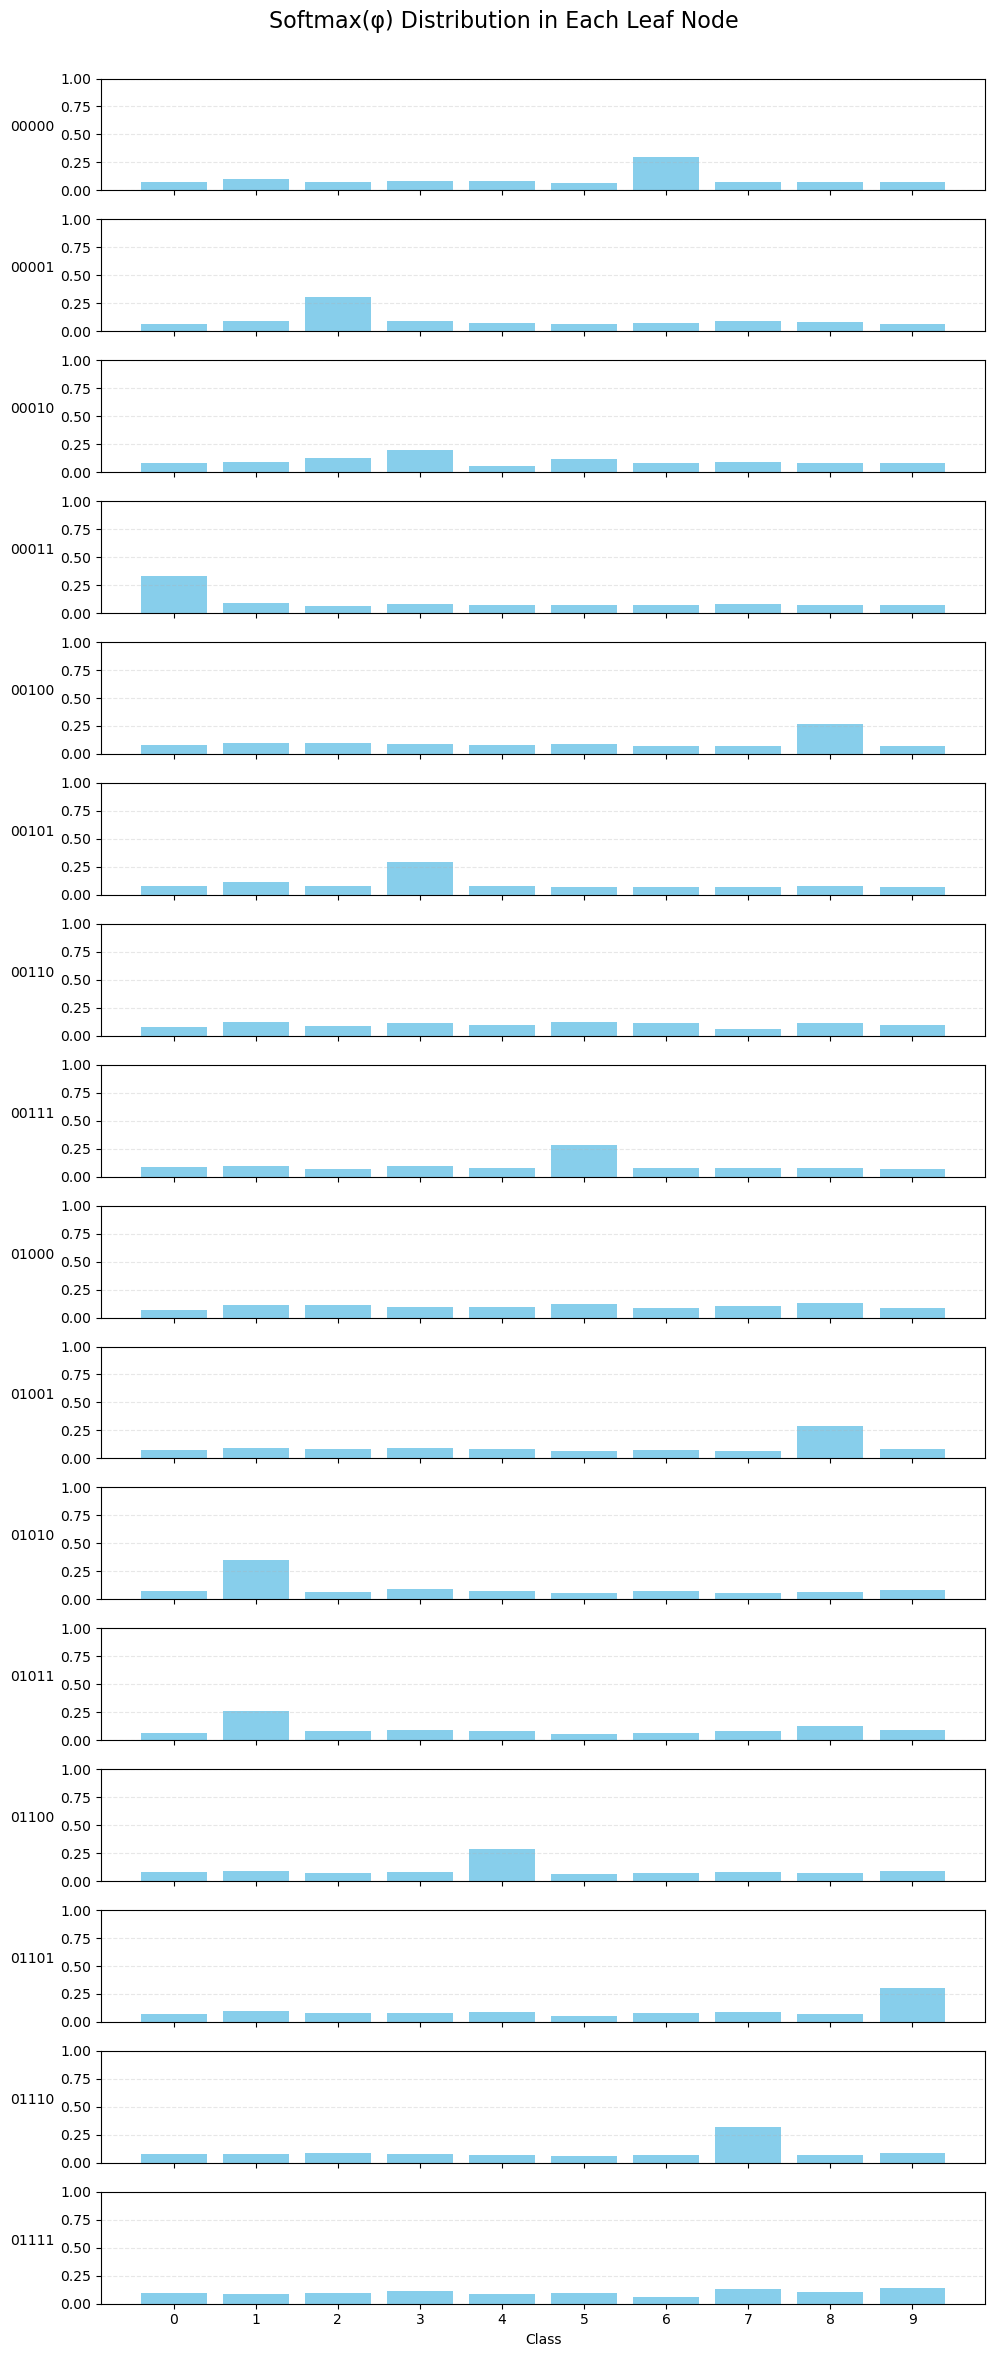

In [20]:
# 언러닝 전 리프노드 시각화화
import matplotlib.pyplot as plt
import numpy as np

def plot_leaf_phi_distribution(tree, sess):
    leaves = [n for n in tree.nodes if n.isLeaf]
    n_classes = sess.run(leaves[0].phi).shape[1]

    n_leaves = len(leaves)
    fig, axes = plt.subplots(n_leaves, 1, figsize=(10, n_leaves * 1.5), sharex=True)

    for i, leaf in enumerate(leaves):
        raw_phi = sess.run(leaf.phi)[0]
        soft_phi = np.exp(raw_phi) / (np.sum(np.exp(raw_phi)) + 1e-8)

        ax = axes[i] if n_leaves > 1 else axes
        ax.bar(range(n_classes), soft_phi, color='skyblue')
        ax.set_ylabel(f'{leaf.id}', rotation=0, labelpad=20)
        ax.set_ylim(0, 1)
        ax.grid(axis='y', linestyle='--', alpha=0.3)

    plt.xticks(range(n_classes))
    plt.xlabel("Class")
    plt.suptitle("Softmax(φ) Distribution in Each Leaf Node", fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

plot_leaf_phi_distribution(tree, sess)

## Unlearning target

00000           | 0.080006
00001           | 0.088696
00010           | 0.199530
00011           | 0.080489
00100           | 0.089231
00101           | 0.294714
00110           | 0.110415
00111           | 0.097212
01000           | 0.093438
01001           | 0.088852
01010           | 0.094644
01011           | 0.089681
01100           | 0.083009
01101           | 0.081207
01110           | 0.079536
01111           | 0.115537


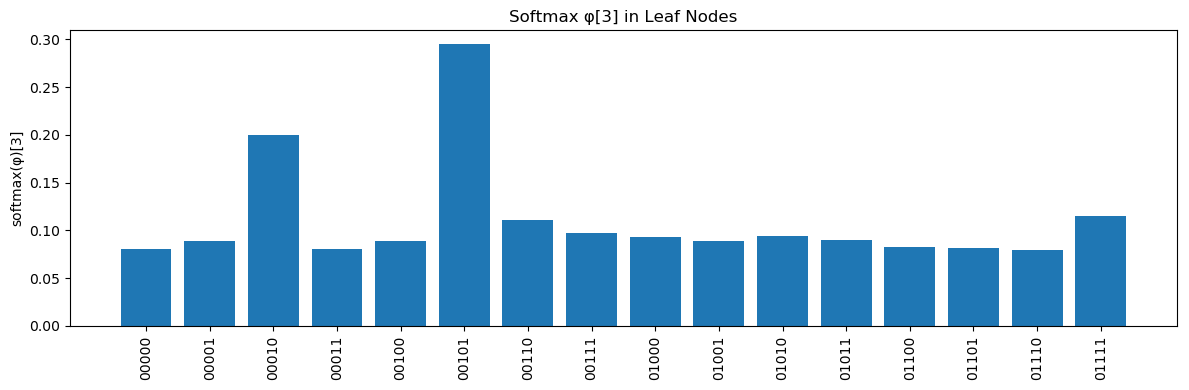

In [51]:
import matplotlib.pyplot as plt

def plot_leaf_node_phi_softmax(tree, sess, target_class=3):
    leaves = [n for n in tree.nodes if n.isLeaf]
    phi_values = []
    node_ids = []

    for leaf in leaves:
        raw_phi = sess.run(leaf.phi)[0]
        soft_phi = np.exp(raw_phi) / (np.sum(np.exp(raw_phi)) + 1e-8)
        phi_values.append(soft_phi[target_class])
        node_ids.append(leaf.id)
        print(f"{leaf.id:<15} | {soft_phi[target_class]:.6f}")

    plt.figure(figsize=(12, 4))
    plt.bar(range(len(phi_values)), phi_values, tick_label=node_ids)
    plt.xticks(rotation=90)
    plt.ylabel(f"softmax(φ)[{target_class}]")
    plt.title(f"Softmax φ[{target_class}] in Leaf Nodes")
    plt.tight_layout()
    plt.show()


plot_leaf_node_phi_softmax(tree=tree, sess=sess, target_class=3)


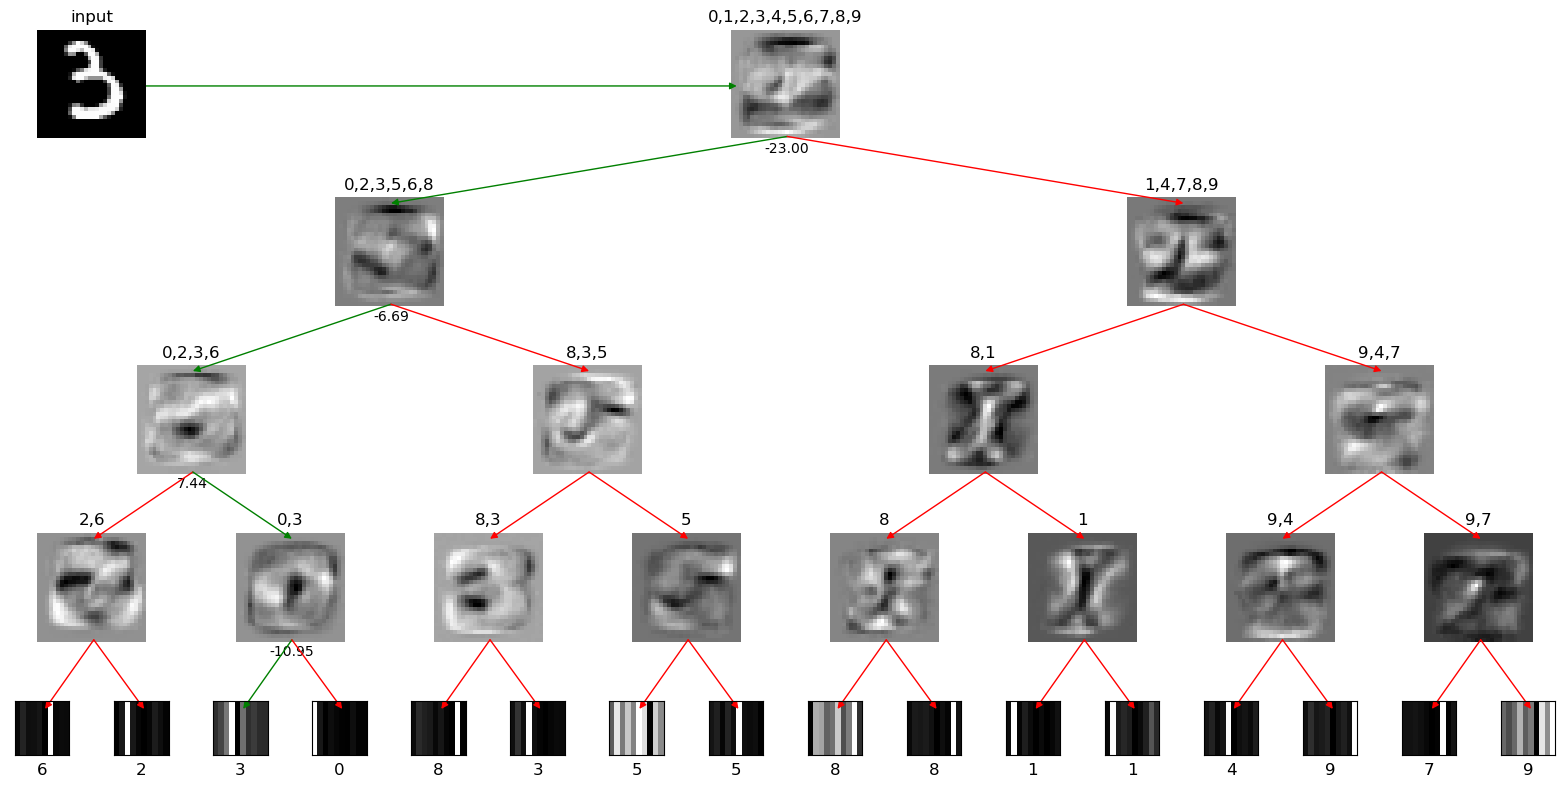

In [15]:
digit = 3

# get (reproducibly) pseudo-random example of chosen digit
np.random.seed(0)
sample_index = np.random.choice(np.where(np.argmax(y_test, axis=1)==digit)[0])
input_img = x_test[sample_index]

draw_tree(sess, tree, img_rows, img_cols, img_chans, input_img=input_img)

In [16]:
# 리프 노드들 중에서 target classs를 가장 강하게 예측하는 리프를 찾음
# 각 타겟 리프에 대해 유사한 (하지만 target_class를 예측하지 않는) 리프 top_k개를 찾음 (코사인 유사도 기반)
# 타겟 클래스의 φ 확률 중 일부 (α 비율)를 유사 리프들로 soft하게 분산시키고, 나머지는 자신에게 남김
# 리프가 도달하는 경로에 있는 inner node들의 weight를 soft pruning 방식으로 약화
# 변경된 φ와 weight 저장

# target_class를 예측하는 리프를 찾고 → 그 φ 확률을 유사한 다른 리프로 soft하게 분산

# 해당 리프의 경로를 pruning하여 영향력을 감소시키고 → 여전히 남은 φ 값은 soft하게 suppress (모델 내부에서 특정 클래스 (target class)에 대한 예측을 의도적으로 낮추는 것)

# 결과적으로, 모델이 target_class를 예측하지 못하게 유도하면서도 전체 구조는 유지

def unlearn_target_class(tree, sess, target_class=3, top_k=3, alpha=0.3, pruning_rate=0.7, save_path=None):
    import numpy as np
    from sklearn.metrics.pairwise import cosine_similarity

    leaves = [n for n in tree.nodes if n.isLeaf]
    phi_values = sess.run([leaf.phi for leaf in leaves])

    target_leaves = []
    for leaf, phi in zip(leaves, phi_values):
        if np.argmax(phi) == target_class:
            target_leaves.append(leaf)

    similar_map = {}
    for t_leaf in target_leaves:
        t_phi = sess.run(t_leaf.phi).reshape(1, -1)
        sims = []
        for other_leaf in leaves:
            if other_leaf == t_leaf:
                continue
            o_phi = sess.run(other_leaf.phi).reshape(1, -1)
            # 🔒 분산 대상 리프의 φ[0]이 이미 dominant한 경우 제외
            if np.argmax(o_phi) == target_class or o_phi[0, target_class] > 0.2:
                continue
            sim = cosine_similarity(t_phi, o_phi)[0, 0]
            sims.append((other_leaf, sim))
        similar_map[t_leaf] = sorted(sims, key=lambda x: -x[1])[:top_k]

    for t_leaf in target_leaves:
        t_phi_val = sess.run(t_leaf.phi)
        phi_tc = t_phi_val[0, target_class]
        residual_phi = np.copy(t_phi_val)

        redistributed_value = phi_tc * alpha
        residual_phi[0, target_class] = phi_tc * (1 - alpha)

        total_sim = sum([s for _, s in similar_map[t_leaf]]) + 1e-8
        for other_leaf, sim in similar_map[t_leaf]:
            ratio = sim / total_sim
            addition = redistributed_value * ratio

            other_phi_val = sess.run(other_leaf.phi)
            updated_phi = np.copy(other_phi_val)
            updated_phi[0, target_class] += addition

            # ⚠️ 추가 조건: 업데이트 후에도 target_class가 max가 되면 적용 안 함
            if np.argmax(updated_phi) == target_class:
                continue

            updated_phi /= np.sum(updated_phi) + 1e-8
            phi_var = [v for v in tf.global_variables()
                       if v.name.startswith('phi_' + other_leaf.id)][0]
            sess.run(tf.assign(phi_var, updated_phi.astype(np.float32)))

        residual_phi /= np.sum(residual_phi) + 1e-8
        phi_var = [v for v in tf.global_variables()
                   if v.name.startswith('phi_' + t_leaf.id)][0]
        sess.run(tf.assign(phi_var, residual_phi.astype(np.float32)))

        def find_path_to_leaf(root, target):
            path = []
            def dfs(node, current_path):
                if node == target:
                    path.extend(current_path)
                    return True
                if node.isLeaf:
                    return False
                return dfs(node.leftChild, current_path + [node]) or dfs(node.rightChild, current_path + [node])
            dfs(tree.root, [])
            return path

        importance = float(t_phi_val[0, target_class])
        pruning_scale = 1.0 - importance * pruning_rate

        path_nodes = find_path_to_leaf(tree.root, t_leaf)
        for node in path_nodes:
            dense_vars = [v for v in tf.global_variables()
                          if v.name.startswith('dense_' + node.id)]
            for var in dense_vars:
                current_val = sess.run(var)
                weakened_val = current_val * pruning_scale
                sess.run(tf.assign(var, weakened_val))

    # 🔧 전체 리프 노드 중 φ[target_class]가 여전히 높은 경우 soft suppression 추가
    for leaf, phi_val in zip(leaves, phi_values):
        if leaf in target_leaves:
            continue
        if phi_val[0, target_class] > 0.01:
            adjusted_phi = np.copy(phi_val)
            adjusted_phi[0, target_class] *= (1 - alpha)
            adjusted_phi /= np.sum(adjusted_phi) + 1e-8
            phi_var = [v for v in tf.global_variables() if v.name.startswith('phi_' + leaf.id)][0]
            sess.run(tf.assign(phi_var, adjusted_phi.astype(np.float32)))

    print("✅ Soft redistribution unlearning applied to class", target_class)

    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        tree.save_variables(sess, save_path)
        print(f"📁 Unlearned model saved to: {save_path}")



In [19]:
x_train_flat = x_train.reshape(x_train.shape[0], -1)
# 테스트 데이터도 동일하게 처리
x_test_flat = x_test.reshape(x_test.shape[0], -1)

target_class = 3

# 예시 경로 지정
# save_path = "result/unlearned"
save_path = "result/mnist/unlearned"

# 언러닝 및 저장 실행
unlearn_target_class(tree, sess, target_class=3, top_k=3, alpha=0.5, pruning_rate=0.7, save_path=save_path)

from sklearn.metrics import precision_score, recall_score, f1_score, classification_report
import numpy as np

# 전체 테스트셋 평가
feed_dict = {tree.input_layer: x_test_flat}
predictions = sess.run(tree.output_layer, feed_dict=feed_dict)
pred_classes = np.argmax(predictions, axis=1)
true_classes = np.argmax(y_test, axis=1)

accuracy = np.mean(pred_classes == true_classes)
print(f"\nTest accuracy after unlearning: {accuracy:.4f}")

# 전체 성능 지표
print("\n=== Overall Performance ===")
print(f"Precision (macro): {precision_score(true_classes, pred_classes, average='macro'):.4f}")
print(f"Recall    (macro): {recall_score(true_classes, pred_classes, average='macro'):.4f}")
print(f"F1-score  (macro): {f1_score(true_classes, pred_classes, average='macro'):.4f}")
print("\n=== Full Classification Report ===")

# 🎯 타겟 클래스에 대한 성능
target_class = 3
target_mask = np.argmax(y_test, axis=1) == target_class
if np.sum(target_mask) > 0:
    print("\n=== Target Class Performance ===")
    target_acc = np.mean(pred_classes[target_mask] == true_classes[target_mask])
    print(f"Target class accuracy: {target_acc:.4f}")
    print(f"Target class precision: {precision_score(true_classes[target_mask], pred_classes[target_mask], average='macro', zero_division=0):.4f}")
    print(f"Target class recall:    {recall_score(true_classes[target_mask], pred_classes[target_mask], average='macro', zero_division=0):.4f}")
    print(f"Target class F1-score:  {f1_score(true_classes[target_mask], pred_classes[target_mask], average='macro', zero_division=0):.4f}")

# ✅ 비타겟 클래스 성능
non_target_mask = np.argmax(y_test, axis=1) != target_class
if np.sum(non_target_mask) > 0:
    print("\n=== Non-Target Class Performance ===")
    non_target_acc = np.mean(pred_classes[non_target_mask] == true_classes[non_target_mask])
    print(f"Non-target class accuracy: {non_target_acc:.4f}")
    print(f"Non-target precision: {precision_score(true_classes[non_target_mask], pred_classes[non_target_mask], average='macro', zero_division=0):.4f}")
    print(f"Non-target recall:    {recall_score(true_classes[non_target_mask], pred_classes[non_target_mask], average='macro', zero_division=0):.4f}")
    print(f"Non-target F1-score:  {f1_score(true_classes[non_target_mask], pred_classes[non_target_mask], average='macro', zero_division=0):.4f}")


✅ Soft redistribution + dominant boost unlearning applied to class 3
📁 Unlearned model saved to: result/mnist/unlearned

Test accuracy after unlearning: 0.8099

=== Overall Performance ===
Precision (macro): 0.7517
Recall    (macro): 0.8094
F1-score  (macro): 0.7742

=== Full Classification Report ===

=== Target Class Performance ===
Target class accuracy: 0.0000
Target class precision: 0.0000
Target class recall:    0.0000
Target class F1-score:  0.0000

=== Non-Target Class Performance ===
Non-target class accuracy: 0.9009
Non-target precision: 0.9003
Non-target recall:    0.8994
Non-target F1-score:  0.8989


c:\Users\kimdd\anaconda3\envs\unlearning\lib\site-packages\sklearn\metrics\_classification.py:1318: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [31]:
def inspect_similar_leaves(tree, sess, target_class=0, top_k=1):
    from sklearn.metrics.pairwise import cosine_similarity
    import numpy as np

    leaves = [n for n in tree.nodes if n.isLeaf]
    phi_values = sess.run([leaf.phi for leaf in leaves])

    print(f"\n🔎 Target class = {target_class}")

    for i, (leaf, phi) in enumerate(zip(leaves, phi_values)):
        if np.argmax(phi) != target_class:
            continue

        print(f"\n📍 Leaf ID {leaf.id} predicts class {target_class}")
        print(f"    φ = {np.round(phi[0], 3)}")

        sims = []
        for other_leaf, other_phi in zip(leaves, phi_values):
            if other_leaf == leaf:
                continue
            if np.argmax(other_phi) == target_class:
                continue
            sim = cosine_similarity(phi.reshape(1, -1), other_phi.reshape(1, -1))[0, 0]
            sims.append((other_leaf, other_phi, sim))

        sims_sorted = sorted(sims, key=lambda x: -x[2])[:top_k]
        for rank, (sim_leaf, sim_phi, score) in enumerate(sims_sorted, 1):
            pred_class = np.argmax(sim_phi)
            top_classes = np.argsort(sim_phi[0])[::-1][:3]
            top_probs = sim_phi[0][top_classes]
            top_view = ", ".join(f"{c}:{top_probs[i]:.2f}" for i, c in enumerate(top_classes))
            print(f"  ↪ Top-{rank} similar leaf: ID={sim_leaf.id}, sim={score:.4f}, "
                  f"predicts class={pred_class} | φ[top] = [{top_view}]")


inspect_similar_leaves(tree, sess, target_class=3, top_k=3)


🔎 Target class = 3


🔍 [After Unlearning] Evaluation on test set
Evaluation Results:
 - Accuracy:  71.63%
 - Precision: 62.01%
 - Recall:    71.39%
 - F1-Score:  65.15%
📷 Sample #1 (class 3)


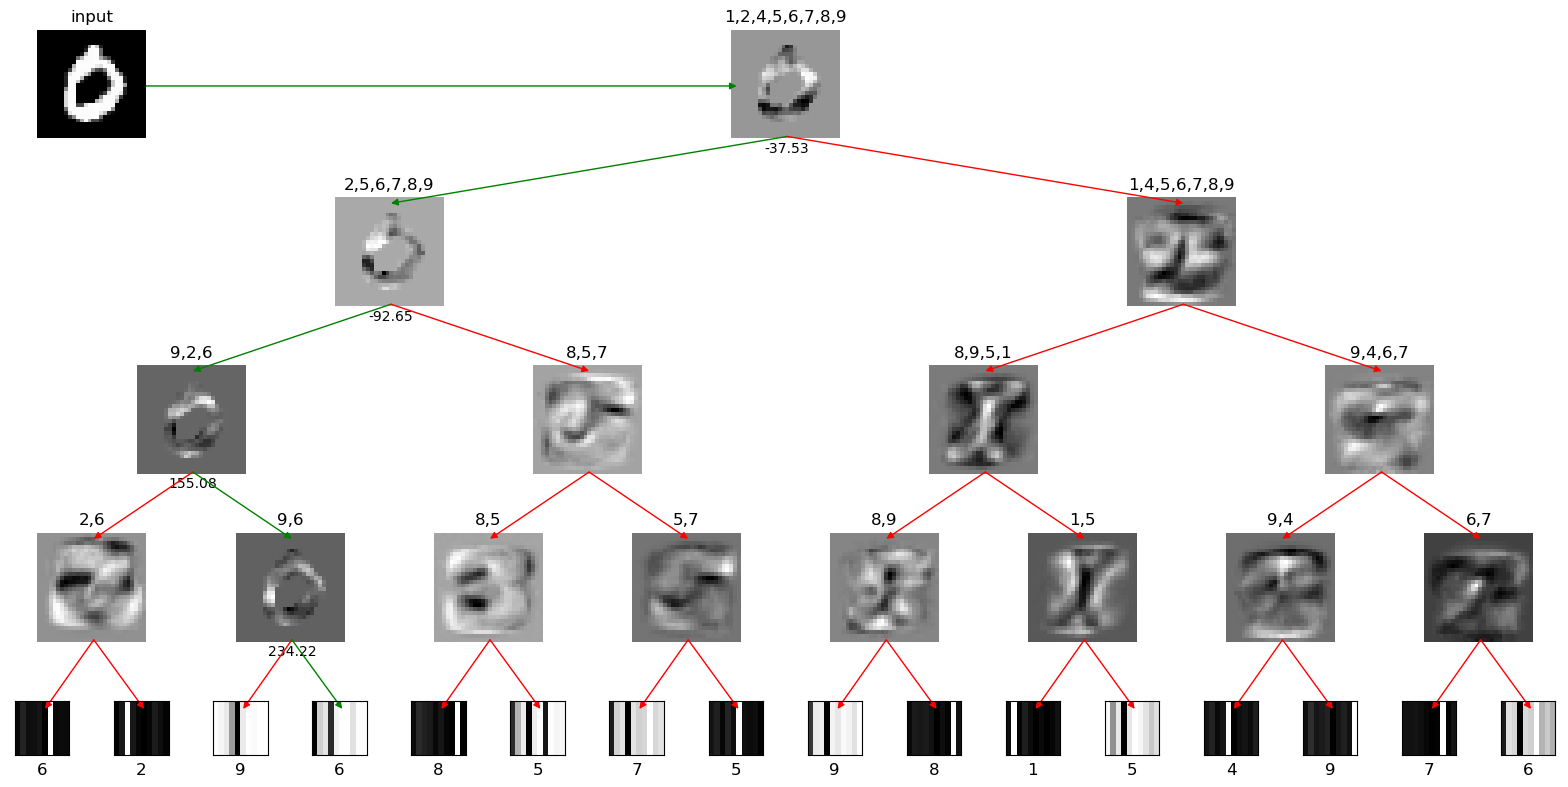

In [78]:
# 언러닝 후 정확도 평가
print("🔍 [After Unlearning] Evaluation on test set")
tree.evaluate(x_test_flat, y_test, batch_size=batch_size)

# 동일한 digit = 3 입력 이미지로 시각화
digit = 0
target_indices = np.where(np.argmax(y_test, axis=1) == digit)[0]

# 언러닝 후 트리 시각화 저장
for i in range(1):
    x_sample = x_test[target_indices[i]]  # (28, 28)
    print(f"📷 Sample #{i+1} (class {target_class})"),
    draw_tree(sess, tree, 28, 28, 1, input_img=x_sample, show_correlation=True)
    # draw_tree(sess, tree, 28, 28, 1, input_img=x_sample, show_correlation=True, savepath='tree_visualization_after_unlearning(mnist)2.pdf')

In [56]:
def debug_internal_phi(tree, sess):
    internal_nodes = [n for n in tree.nodes if not n.isLeaf]
    for node in internal_nodes:
        if hasattr(node, 'phi'):
            val = sess.run(node.phi)
            print(f"Node ID: {node.id}, φ shape: {val.shape}, φ sum: {np.sum(val)}, φ: {val}")
        else:
            print(f"Node ID: {node.id} has no φ.")

debug_internal_phi(tree=tree, sess=sess)

Node ID: 0 has no φ.
Node ID: 00 has no φ.
Node ID: 01 has no φ.
Node ID: 000 has no φ.
Node ID: 001 has no φ.
Node ID: 010 has no φ.
Node ID: 011 has no φ.
Node ID: 0000 has no φ.
Node ID: 0001 has no φ.
Node ID: 0010 has no φ.
Node ID: 0011 has no φ.
Node ID: 0100 has no φ.
Node ID: 0101 has no φ.
Node ID: 0110 has no φ.
Node ID: 0111 has no φ.


00000           | 0.080006
00001           | 0.088696
00010           | 0.076471
00011           | 0.080489
00100           | 0.089231
00101           | 0.090545
00110           | 0.090169
00111           | 0.097212
01000           | 0.092635
01001           | 0.088852
01010           | 0.094644
01011           | 0.092460
01100           | 0.083009
01101           | 0.081207
01110           | 0.079536
01111           | 0.090164


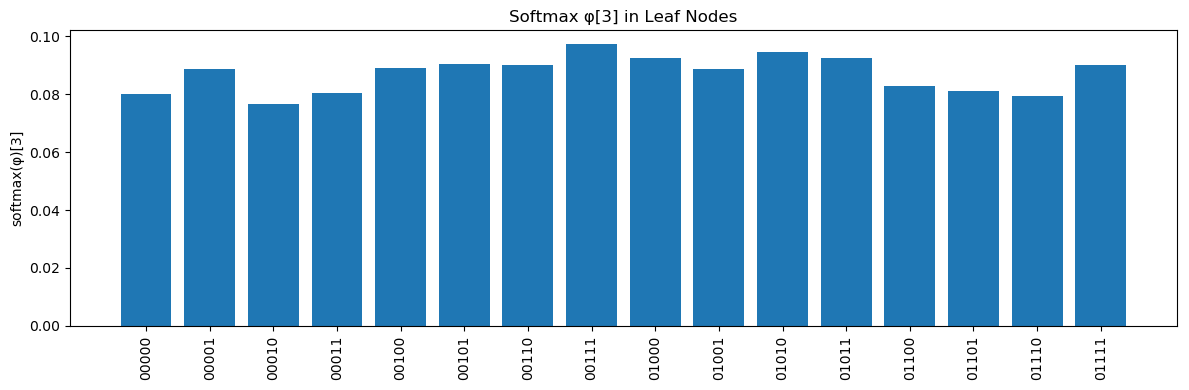

In [57]:
import matplotlib.pyplot as plt

def plot_leaf_node_phi_softmax(tree, sess, target_class=3):
    leaves = [n for n in tree.nodes if n.isLeaf]
    phi_values = []
    node_ids = []

    for leaf in leaves:
        raw_phi = sess.run(leaf.phi)[0]
        soft_phi = np.exp(raw_phi) / (np.sum(np.exp(raw_phi)) + 1e-8)
        phi_values.append(soft_phi[target_class])
        node_ids.append(leaf.id)
        print(f"{leaf.id:<15} | {soft_phi[target_class]:.6f}")

    plt.figure(figsize=(12, 4))
    plt.bar(range(len(phi_values)), phi_values, tick_label=node_ids)
    plt.xticks(rotation=90)
    plt.ylabel(f"softmax(φ)[{target_class}]")
    plt.title(f"Softmax φ[{target_class}] in Leaf Nodes")
    plt.tight_layout()
    plt.show()


plot_leaf_node_phi_softmax(tree=tree, sess=sess, target_class=3)


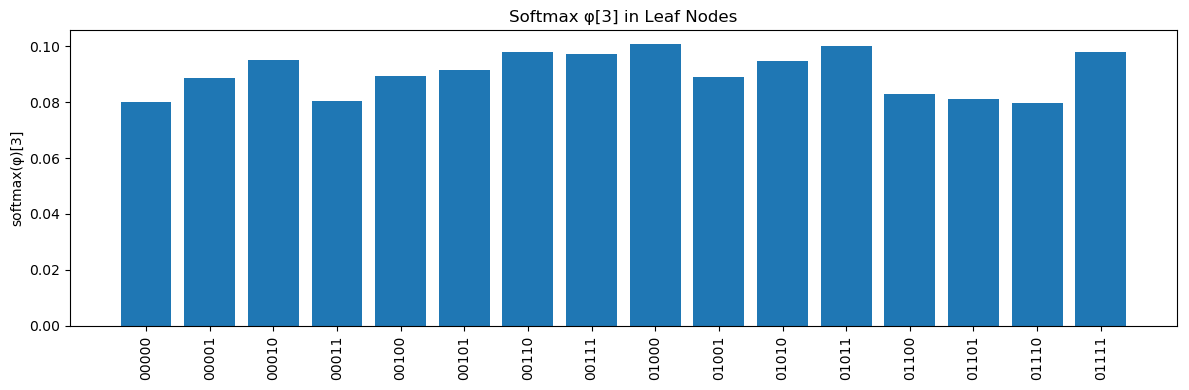

In [23]:
import matplotlib.pyplot as plt

def plot_leaf_node_phi_softmax(tree, sess, target_class=3):
    leaves = [n for n in tree.nodes if n.isLeaf]
    phi_values = []
    node_ids = []

    for leaf in leaves:
        raw_phi = sess.run(leaf.phi)[0]
        soft_phi = np.exp(raw_phi) / (np.sum(np.exp(raw_phi)) + 1e-8)
        phi_values.append(soft_phi[target_class])
        node_ids.append(leaf.id)

    plt.figure(figsize=(12, 4))
    plt.bar(range(len(phi_values)), phi_values, tick_label=node_ids)
    plt.xticks(rotation=90)
    plt.ylabel(f"softmax(φ)[{target_class}]")
    plt.title(f"Softmax φ[{target_class}] in Leaf Nodes")
    plt.tight_layout()
    plt.show()


plot_leaf_node_phi_softmax(tree=tree, sess=sess, target_class=3)


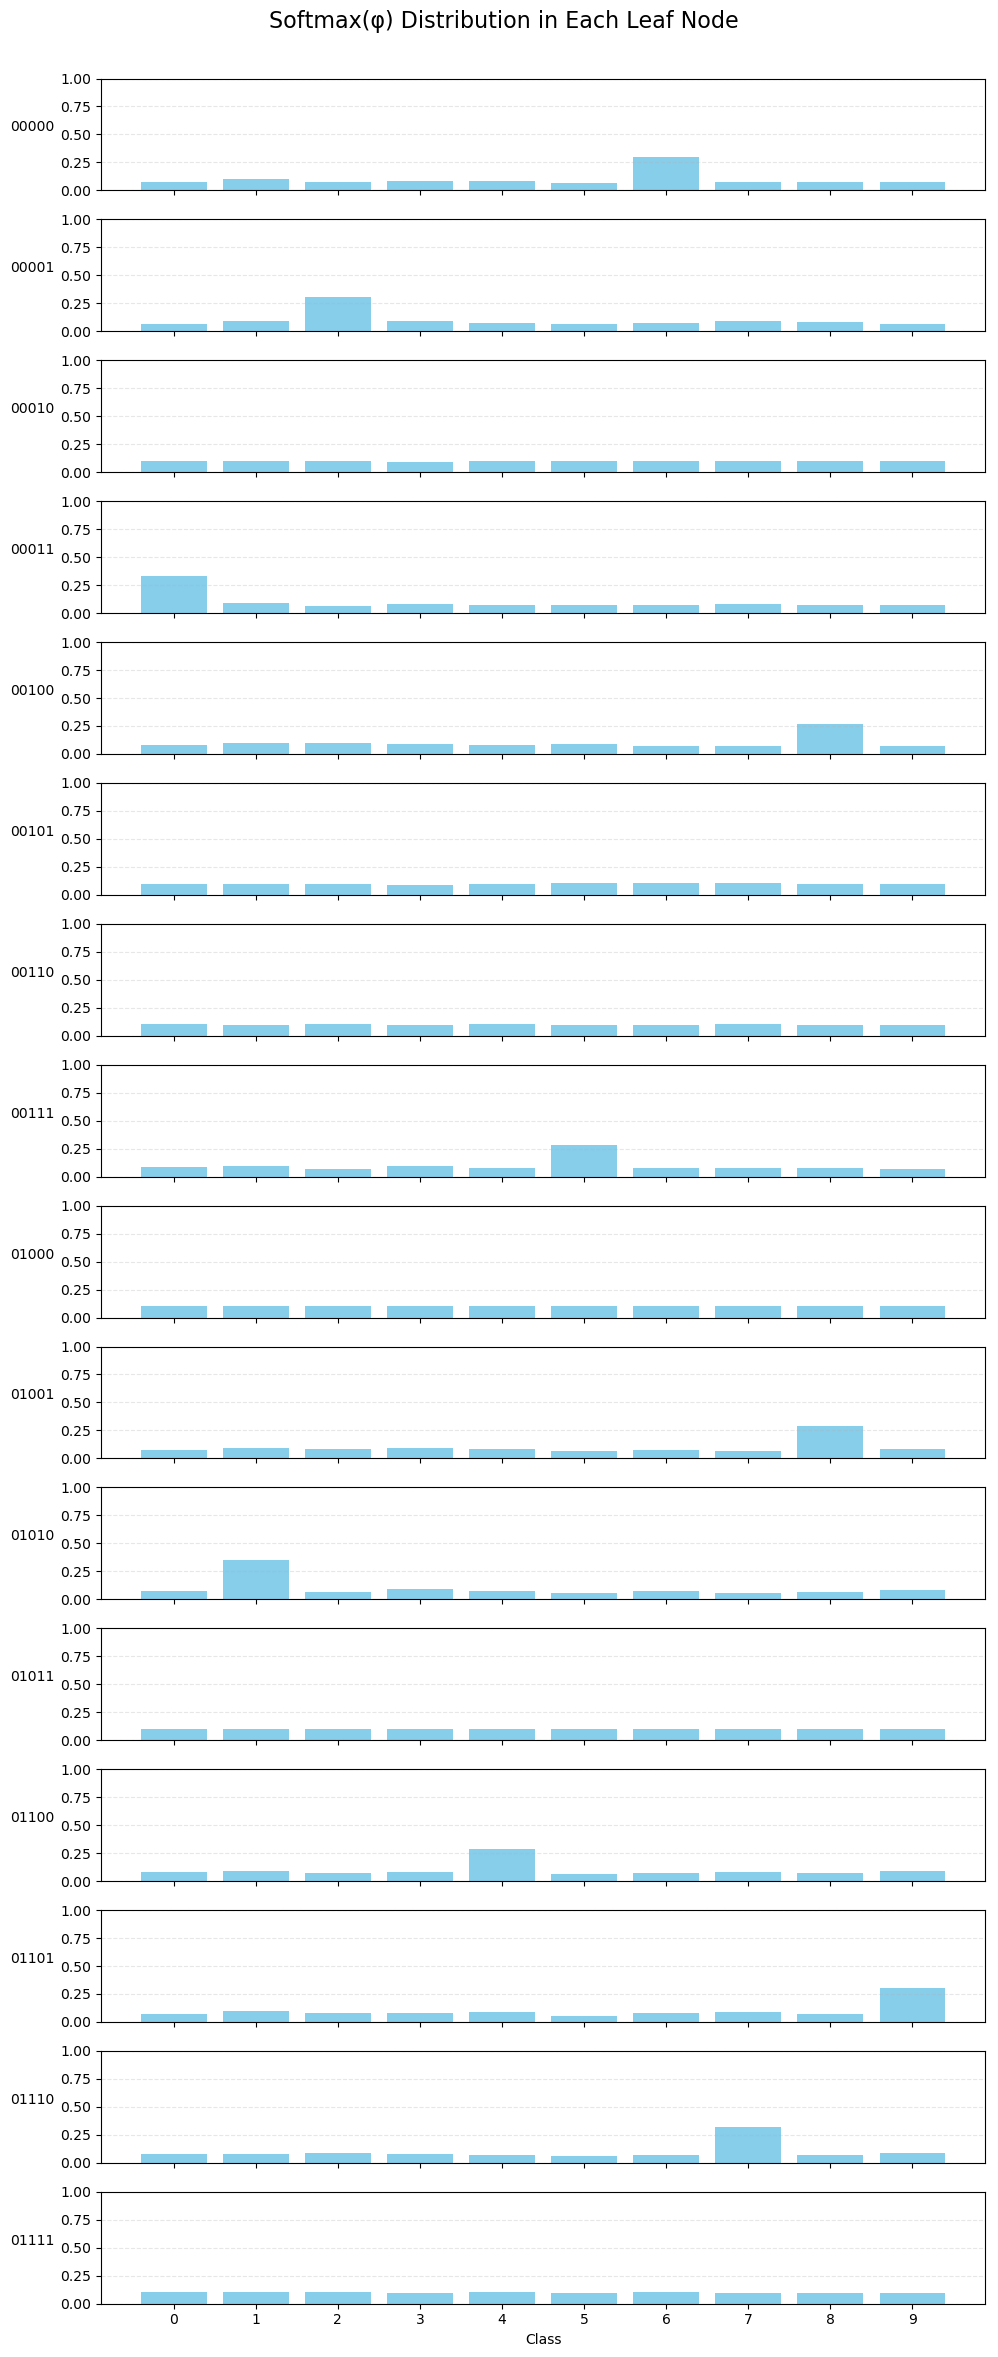

In [43]:
import matplotlib.pyplot as plt
import numpy as np

def plot_leaf_phi_distribution(tree, sess):
    leaves = [n for n in tree.nodes if n.isLeaf]
    n_classes = sess.run(leaves[0].phi).shape[1]

    n_leaves = len(leaves)
    fig, axes = plt.subplots(n_leaves, 1, figsize=(10, n_leaves * 1.5), sharex=True)

    for i, leaf in enumerate(leaves):
        raw_phi = sess.run(leaf.phi)[0]
        soft_phi = np.exp(raw_phi) / (np.sum(np.exp(raw_phi)) + 1e-8)

        ax = axes[i] if n_leaves > 1 else axes
        ax.bar(range(n_classes), soft_phi, color='skyblue')
        ax.set_ylabel(f'{leaf.id}', rotation=0, labelpad=20)
        ax.set_ylim(0, 1)
        ax.grid(axis='y', linestyle='--', alpha=0.3)

    plt.xticks(range(n_classes))
    plt.xlabel("Class")
    plt.suptitle("Softmax(φ) Distribution in Each Leaf Node", fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

plot_leaf_phi_distribution(tree, sess)